Exploratory Data Analysis of the Heart Failure Dataaset 

Age - Age of the patient  [Years]
Sex - Male or Female [Binary]
Anaemia - Decrease of RBC's or Hemoglobulin [Boolean]
High Blood Pressure - [Boolean]
Creatinine Phosphokinase - Level of CPK enzyme in the blood [mcg/L]
Diabetes - [Boolean]
Ejection Fraction - Percentage of Blood leaving the heart after each contraction [percentage]
Platelets - [Kgiloplatelets/ml]
Serum Creatinine - Level of creatinine in the blood [mg/dl]
Serum Sodium - Level of sodium in the blood  [mEq/L]
SMoking - [Boolean]
Time - Follow up period [Days]
Death event (Target)- If the patient died during the follow up period. Survived patients (0) and Dead (1)

In [54]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [7]:
#load the dataset
df = pd.read_csv('C:\EDA_HFR\heart_failure_clinical_records_dataset.csv')

<>:2: SyntaxWarning: "\E" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\E"? A raw string is also an option.
<>:2: SyntaxWarning: "\E" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\E"? A raw string is also an option.
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_42900\265555544.py:2: SyntaxWarning: "\E" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\E"? A raw string is also an option.
  df = pd.read_csv('C:\EDA_HFR\heart_failure_clinical_records_dataset.csv')


In [8]:
#display the first 10 rows of the dataset 
df.head(10)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
5,90.0,1,47,0,40,1,204000.00,2.1,132,1,1,8,1
6,75.0,1,246,0,15,0,127000.00,1.2,137,1,0,10,1
7,60.0,1,315,1,60,0,454000.00,1.1,131,1,1,10,1
8,65.0,0,157,0,65,0,263358.03,1.5,138,0,0,10,1
9,80.0,1,123,0,35,1,388000.00,9.4,133,1,1,10,1


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [ ]:
#dimensions of the dataset
df.shape
#all 299 patients are heart failure patients and 13 features are used to predict the target variable 'DEATH_EVENT'

(299, 13)

In [10]:
#descriptive statistics of the dataset
df.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


Average Age  = 61
43% of the patients are Anaemic 
41 % of the patients are diabetic 
35% patients have high blood pressure


In [11]:
#display the column names of the dataset 
df.columns

Index(['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
       'ejection_fraction', 'high_blood_pressure', 'platelets',
       'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time',
       'DEATH_EVENT'],
      dtype='str')

In [13]:
df_copy = df.copy()

In [25]:
#remove duplicate rows 
df_copy.drop_duplicates().sum()

age                         1.818933e+04
anaemia                     1.290000e+02
creatinine_phosphokinase    1.739700e+05
diabetes                    1.250000e+02
ejection_fraction           1.138700e+04
high_blood_pressure         1.050000e+02
platelets                   7.874405e+07
serum_creatinine            4.167700e+02
serum_sodium                4.085100e+04
sex                         1.940000e+02
smoking                     9.600000e+01
time                        3.894800e+04
DEATH_EVENT                 9.600000e+01
dtype: float64

In [26]:
#remove missing values 
df_copy.dropna().sum()

age                         1.818933e+04
anaemia                     1.290000e+02
creatinine_phosphokinase    1.739700e+05
diabetes                    1.250000e+02
ejection_fraction           1.138700e+04
high_blood_pressure         1.050000e+02
platelets                   7.874405e+07
serum_creatinine            4.167700e+02
serum_sodium                4.085100e+04
sex                         1.940000e+02
smoking                     9.600000e+01
time                        3.894800e+04
DEATH_EVENT                 9.600000e+01
dtype: float64

Exploratory Data Analysis 

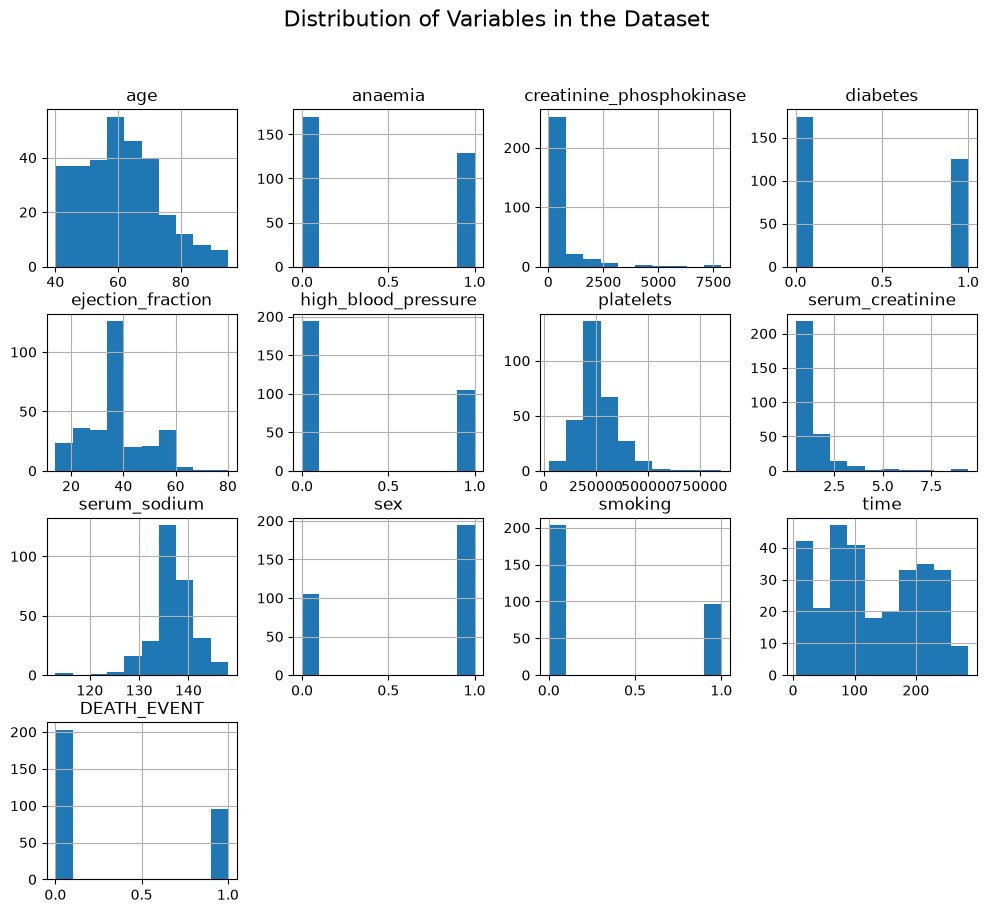

In [16]:
#visualisation using histogram 
#using histogram to visualise the distribution of variables in the dataset (used for numerical variables)
df.hist(figsize=(12,10))
plt.suptitle('Distribution of Variables in the Dataset', fontsize=16)
plt.tight_layout
plt.show()

In [18]:
#Visualisation for categorical variables 
cat_var =[
    col for col in df_copy.columns
    if df_copy[col].nunique() == 2
]
cat_var

['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT']

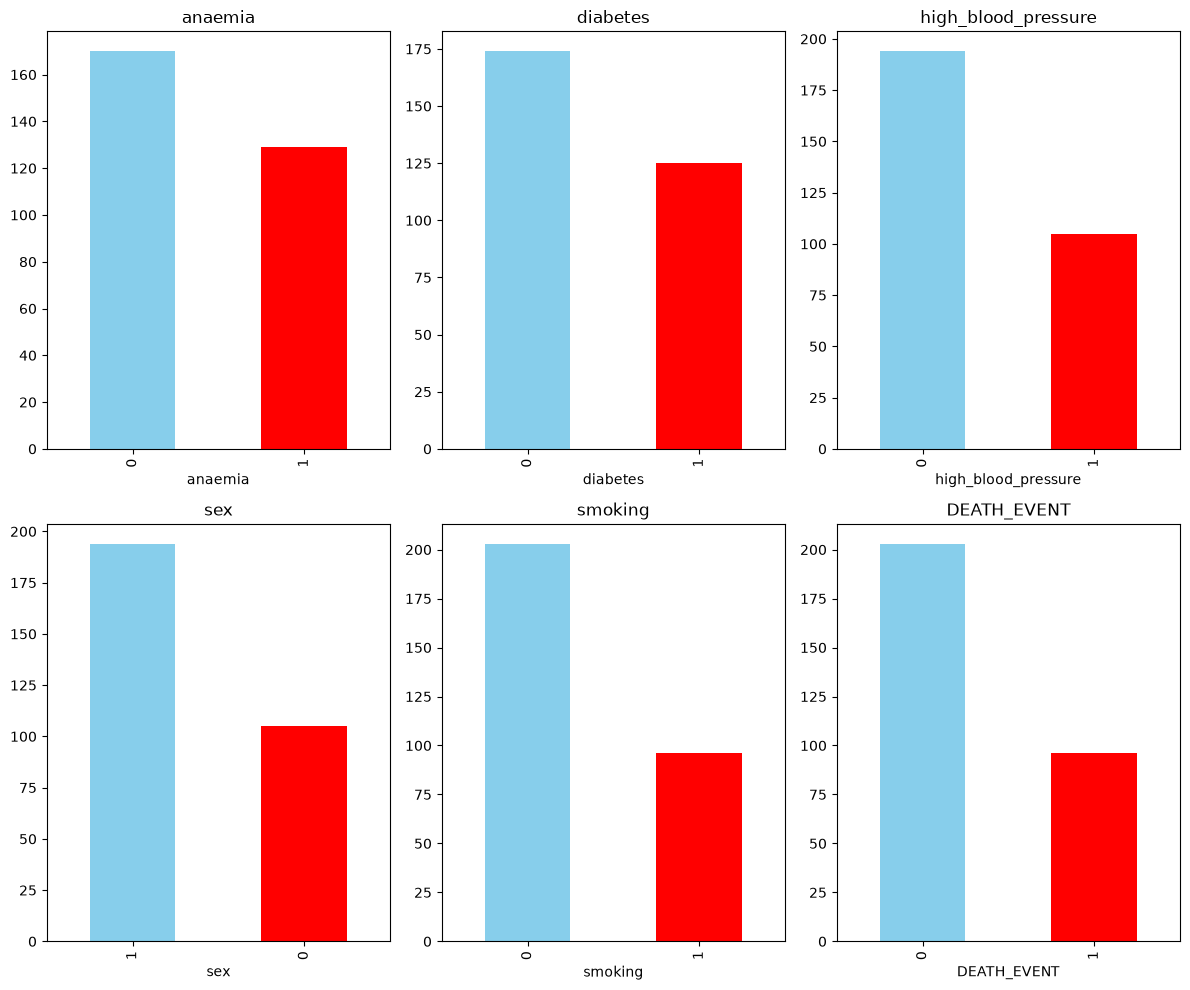

In [24]:
cat_var = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT']
plt.figure(figsize=(12,10))
for i,col in enumerate(cat_var,1):
   plt.subplot(2, 3, i)
   df[col].value_counts().plot(kind='bar', color=['skyblue', 'red'])
   plt.title(col)
plt.tight_layout()
plt.show()

In [30]:
#Distribution of Age
patient_died = df[df['DEATH_EVENT']== 1]
patient_died
patient_died['age'].describe()

count    96.000000
mean     65.215281
std      13.214556
min      42.000000
25%      55.000000
50%      65.000000
75%      75.000000
max      95.000000
Name: age, dtype: float64

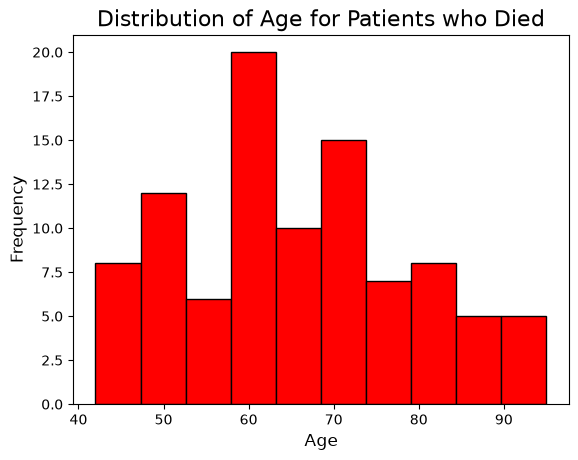

In [38]:
patient_died['age'].plot(kind='hist', bins=10, color='red', edgecolor='black')
plt.title('Distribution of Age for Patients who Died', fontsize=16)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

In [44]:
#Gender Distributiion among the dead patients 
#Here 64 % of men died due to heart failure compared to men. 
gend_dist =patient_died['sex'].value_counts(True)
gend_dist


sex
1    0.645833
0    0.354167
Name: proportion, dtype: float64

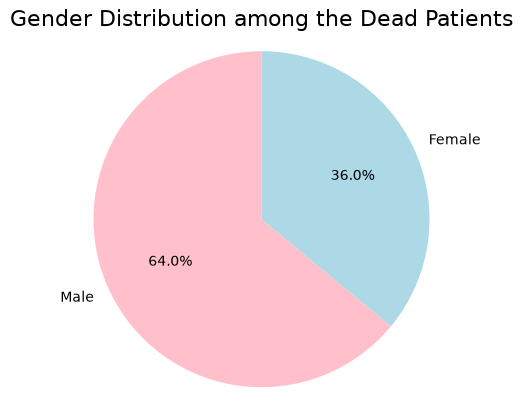

In [47]:
#creating a pie chart to visualise the gender distribution among the dead patients
gender = {'Male':64, 'Female':36}

#create figure and axis 
fig, ax = plt.subplots()
labels = [sex for sex in gender] #data for the pie chart
sizes = list(gender.values())
colours = ['pink', 'lightblue']
ax.pie(sizes, labels=labels, colors=colours, autopct='%1.1f%%', startangle=90)
ax.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.    
plt.title('Gender Distribution among the Dead Patients', fontsize=16)
plt.show()

In [50]:
#difference in the serum creatinine and seru sodium levels between the patients who died and those who survived
df.groupby('DEATH_EVENT')[['serum_creatinine', 'serum_sodium']].mean()

,serum_creatinine,serum_sodium
DEATH_EVENT,,
0,1.184877,137.216749
1,1.835833,135.375000


Here the patients who died had higher mean concentration of creatinine compared to people who survived heart failure. 
Lower concentration of sodium is an indicator for heart failure and here the mean concentration of serum sodium 
was lower in patients who died compared to who survived. 

We can also visualise the difference in the levels of serum creatinine and serum sodium using boxplots. Here we will use Seaborn to create a boxplot. 

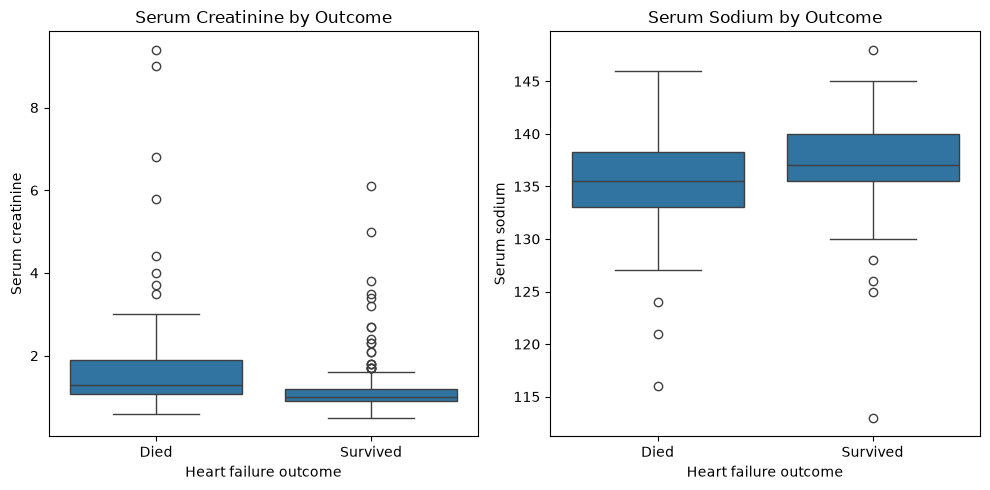

In [56]:

# Give the outcome codes readable labels
df["Outcome"] = df["DEATH_EVENT"].map({0: "Survived", 1: "Died"})

# Put both measurements into separate panels
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(data=df, x="Outcome", y="serum_creatinine", ax=axes[0])
axes[0].set_title("Serum Creatinine by Outcome")
axes[0].set_xlabel("Heart failure outcome")
axes[0].set_ylabel("Serum creatinine")

sns.boxplot(data=df, x="Outcome", y="serum_sodium", ax=axes[1])
axes[1].set_title("Serum Sodium by Outcome")
axes[1].set_xlabel("Heart failure outcome")
axes[1].set_ylabel("Serum sodium")

plt.tight_layout()
plt.show()